#### **MatchLens: Goal & Discipline Tactical Analysis**
This notebook loads cached StatsBomb event data for Match ID `18243`, structures the event timeline via `MatchLensTransformer`, and extracts goal-timing distributions and disciplinary risk metrics.

#### **Imports & Setup**

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import plotly.express as px

# Ensure root directory is in sys.path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))

from src.transformer import MatchLensTransformer

# Initialize Transformer
transformer = MatchLensTransformer(raw_data_dir="../data/raw")
MATCH_ID = 18243

print(f"Transformer initialized for Match ID: {MATCH_ID}")

Transformer initialized for Match ID: 18243


#### **Load & Transform Match Events**

In [2]:
# Load raw events and apply feature engineering
df_raw_events = transformer.load_match_events(match_id=MATCH_ID)
df_events = transformer.engineer_features(df_raw_events)

print(f"Total events loaded and transformed: {len(df_events)}")
df_events[['minute', 'period', 'type', 'team', 'player', 'time_bucket', 'half']].head(10)

Total events loaded and transformed: 4708


,minute,period,type,team,player,time_bucket,half
0,0,1,Starting XI,Real Madrid,None,00-15,First Half
1,0,1,Starting XI,Atlético Madrid,None,00-15,First Half
2,0,1,Half Start,Real Madrid,None,00-15,First Half
3,0,1,Half Start,Atlético Madrid,None,00-15,First Half
4,0,1,Pass,Atlético Madrid,Antoine Griezmann,00-15,First Half
5,0,1,Ball Receipt*,Atlético Madrid,Jorge Resurrección Merodio,00-15,First Half
6,0,1,Carry,Atlético Madrid,Jorge Resurrección Merodio,00-15,First Half
7,0,1,Pass,Atlético Madrid,Jorge Resurrección Merodio,00-15,First Half
8,0,1,Pressure,Real Madrid,Karim Benzema,00-15,First Half
9,0,1,Ball Receipt*,Atlético Madrid,Gabriel Fernández Arenas,00-15,First Half


#### **Module A: Goal & Scoring Analysis**

Total goals recorded in Match 18243: 10


,minute,team,player,shot_statsbomb_xg
499,14,Real Madrid,Sergio Ramos García,0.562398
3040,78,Atlético Madrid,Yannick Ferreira Carrasco,0.564575
4688,120,Real Madrid,Lucas Vázquez Iglesias,0.783500
4690,120,Atlético Madrid,Antoine Griezmann,0.783500
4692,121,Real Madrid,Marcelo Vieira da Silva Júnior,0.783500
4694,121,Atlético Madrid,Gabriel Fernández Arenas,0.783500
4696,122,Real Madrid,Gareth Frank Bale,0.783500
4698,123,Atlético Madrid,Saúl Ñíguez Esclapez,0.783500
4700,124,Real Madrid,Sergio Ramos García,0.783500
4704,125,Real Madrid,Cristiano Ronaldo dos Santos Aveiro,0.783500


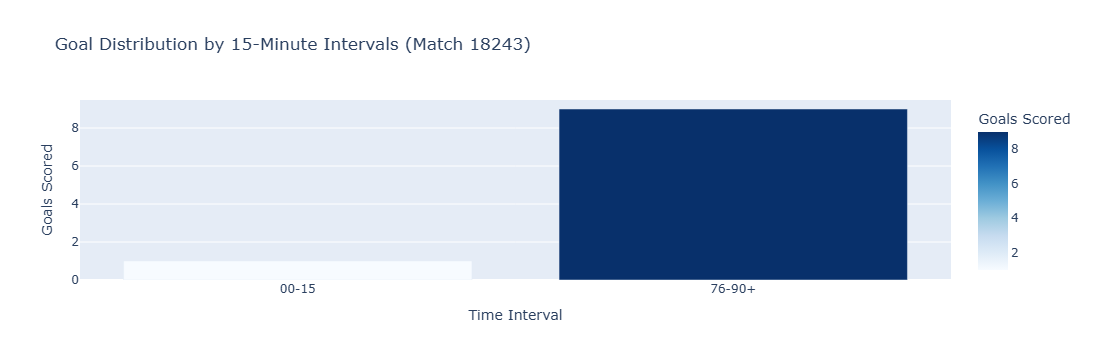

In [4]:
# Filter for goals
df_goals = df_events[df_events['is_goal'] == True].copy()

print(f"Total goals recorded in Match {MATCH_ID}: {len(df_goals)}")
if not df_goals.empty:
    display(df_goals[['minute', 'team', 'player', 'shot_statsbomb_xg']])
    
    # Goals by 15-minute time interval
    goal_intervals = df_goals.groupby('time_bucket').size().reset_index(name='goal_count')
    fig_goals = px.bar(
        goal_intervals, 
        x='time_bucket', 
        y='goal_count',
        title=f"Goal Distribution by 15-Minute Intervals (Match {MATCH_ID})",
        labels={'time_bucket': 'Time Interval', 'goal_count': 'Goals Scored'},
        color='goal_count',
        color_continuous_scale='Blues'
    )
    fig_goals.show()
else:
    print("No goals recorded in this specific match payload (or clean 0-0 match sample).")

#### **Module B: Discipline Analysis & Card Risk**

Total disciplinary actions recorded: 8


,minute,team,player,card_type,time_bucket
332,9,Real Madrid,Daniel Carvajal Ramos,Yellow Card,00-15
2021,46,Real Madrid,Keylor Navas Gamboa,NaN,46-60
2378,60,Atlético Madrid,Fernando José Torres Sanz,Yellow Card,46-60
3018,78,Real Madrid,Carlos Henrique Casimiro,Yellow Card,76-90+
3564,92,Real Madrid,Sergio Ramos García,Yellow Card,76-90+
3566,92,Atlético Madrid,Gabriel Fernández Arenas,NaN,76-90+
3692,92,Real Madrid,Danilo Luiz da Silva,Yellow Card,76-90+
4335,110,Real Madrid,Kléper Laveran Lima Ferreira,Yellow Card,76-90+


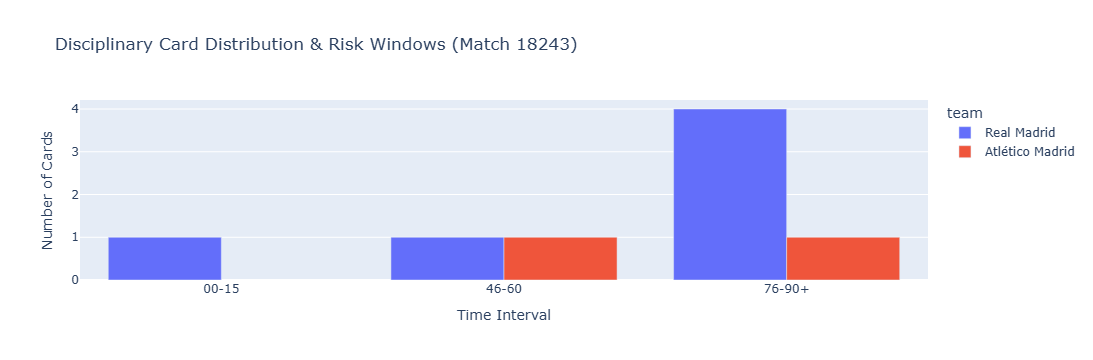

In [5]:
# Filter for disciplinary actions (cards)
df_cards = df_events[df_events['is_card'] == True].copy()

print(f"Total disciplinary actions recorded: {len(df_cards)}")
if not df_cards.empty:
    # Display cards with team, player, and minute
    display(df_cards[['minute', 'team', 'player', 'card_type', 'time_bucket']])
    
    # Discipline clustering by 15-minute intervals (High-Risk Period Analysis)
    card_intervals = df_cards.groupby(['time_bucket', 'team']).size().reset_index(name='card_count')
    
    fig_cards = px.bar(
        card_intervals, 
        x='time_bucket', 
        y='card_count', 
        color='team',
        barmode='group',
        title=f"Disciplinary Card Distribution & Risk Windows (Match {MATCH_ID})",
        labels={'time_bucket': 'Time Interval', 'card_count': 'Number of Cards'}
    )
    fig_cards.show()
else:
    print("No disciplinary cards recorded in this match sample.")